# Provider networks: practitioners, the organizations they bill through, and hospitals

The warehouse holds three public CMS sources that each describe one side of how US health care is organized: NPPES (who is licensed, where, in what specialty), the Medicare Public Provider Enrollment Files (PPEF: who is enrolled in Medicare, and which organization each clinician *reassigns* their Medicare billing to) and the Provider of Services file (POS: every certified hospital). `nppes-over-time graph-build` joins them into one graph, quarter by quarter from February 2016 to September 2026:

* **practitioner** nodes (individual enrollees, by PECOS associate id) and **organization** nodes (organization enrollees, by PECOS associate id, which PECOS issues once per legal entity, so once per tax id);
* **reassignment** edges from a practitioner to each organization that bills Medicare for them;
* **hospital** nodes (active POS hospitals, by CCN) and **hospital_link** edges from a hospital's enrollment to its CCN.

This notebook does three things a health economist would ask of such a graph, each the measure of a published paper, extended over the ten years the PPEF covers:

1. **Group size.** Welch, Cuellar, Stearns and Bindman (*Health Affairs* 2013) and Muhlestein and Smith (*Health Affairs* 2016) measured the shift of physicians from small practices into large groups, defining a group by its Medicare tax id or Physician Compare group id.
2. **Market concentration.** Capps, Dranove and Ody (*Health Affairs* 2017) and Fulton (*Health Affairs* 2017) computed Herfindahl-Hirschman indexes (HHI) of physician organizations within local markets.
3. **Vertical integration.** Luo, Black and others (*HSR* 2024) count physicians billing under hospital-related tax ids; their "basic TIN" variant, a tax id that itself bills as a hospital, is the one public data can reproduce.

`README.md` in this directory summarizes the literature the design follows and what the results show.

## 0. Open the graph

The graph is a directory of Parquet files written by `nppes-over-time graph-build --db <warehouse> --out <dir>` (`$NPPES_GRAPH`, or the repository's `graph/` by default). Every table is an interval table with the warehouse's version semantics: a row holds on date `d` when `effective_date <= d` and `end_date` is NULL or later than `d`, and the interval endpoints are PPEF quarter dates, listed in `quarters.csv`.

In [1]:
import json, os, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
import duckdb
import pandas as pd, numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.figsize": (10, 4), "axes.spines.top": False, "axes.spines.right": False})

GRAPH = Path(os.environ.get("NPPES_GRAPH", "../../graph")).resolve()
manifest = json.load(open(GRAPH / "manifest.json"))
print("graph built", manifest["generated_at"], "from", manifest["warehouse"], "|",
      manifest["quarters"], "quarters", manifest["first_as_of_date"], "to", manifest["last_as_of_date"])

con = duckdb.connect()
con.execute("SET VARIABLE graph = ?", [str(GRAPH)])
for t in ("practitioner", "organization", "hospital", "reassignment", "hospital_link"):
    con.execute(f"CREATE VIEW {t} AS SELECT * FROM read_parquet(getvariable('graph') || '/{t}.parquet')")
con.execute("CREATE VIEW quarters AS SELECT * FROM read_csv(getvariable('graph') || '/quarters.csv')")
con.execute("CREATE TABLE hrr AS SELECT * FROM read_csv('data/zip_hrr_2019.csv', all_varchar = true)")

# Optional, for section 4b: the HHS Medicaid spending extract, from the directory holding the unzipped
# medicaid-provider-spending.csv ($HHS_MEDICAID). The 12 GB CSV is read once into Parquet next to it (a few minutes),
# under a temporary name so an interrupted run leaves nothing. Without it, section 4b runs on an empty table.
HHS = os.environ.get("HHS_MEDICAID")
if HHS:
    HHS = Path(HHS).resolve()
    spending = HHS / "parquet" / "spending.parquet"
    if not spending.exists() or spending.stat().st_mtime < (HHS / "medicaid-provider-spending.csv").stat().st_mtime:
        spending.parent.mkdir(exist_ok=True)
        tmp = spending.with_suffix(".parquet.tmp")
        con.execute(f"""COPY (
            SELECT BILLING_PROVIDER_NPI_NUM AS billing_npi, SERVICING_PROVIDER_NPI_NUM AS servicing_npi,
                   HCPCS_CODE AS hcpcs, strptime(CLAIM_FROM_MONTH, '%Y-%m')::DATE AS month,
                   TOTAL_PATIENTS AS patients, TOTAL_CLAIM_LINES AS claim_lines, TOTAL_PAID AS paid
            FROM read_csv('{HHS}/medicaid-provider-spending.csv',
                          types = {{'BILLING_PROVIDER_NPI_NUM': 'VARCHAR', 'SERVICING_PROVIDER_NPI_NUM': 'VARCHAR', 'HCPCS_CODE': 'VARCHAR',
                                    'CLAIM_FROM_MONTH': 'VARCHAR', 'TOTAL_PATIENTS': 'BIGINT', 'TOTAL_CLAIM_LINES': 'BIGINT', 'TOTAL_PAID': 'DOUBLE'}}))
            TO '{tmp}' (FORMAT parquet, COMPRESSION zstd, ROW_GROUP_SIZE 1000000)""")
        tmp.replace(spending)
    con.execute(f"CREATE VIEW medicaid_spending AS SELECT billing_npi, servicing_npi, month, paid FROM read_parquet('{spending}')")
else:
    con.execute("CREATE TABLE medicaid_spending (billing_npi VARCHAR, servicing_npi VARCHAR, month DATE, paid DOUBLE)")

graph built 2026-10-25T12:50:23 from nppes.e3.duckdb | 43 quarters 2016-02-01 to 2026-09-29


## 1. What the graph holds

Nodes and edges in force on each quarter's date. A reassignment row of the PPEF links one individual *enrollment* to one organization *enrollment*; the graph collapses enrollments to associate ids, so a practitioner enrolled in two states who reassigns to two enrollments of the same group has one edge. `n_reassignment_dropped` counts the PPEF rows that cannot become an edge because one side is missing from that quarter's enrollment file or the receiving side is an individual: about 4,000 a quarter, 0.1 to 0.2 percent.

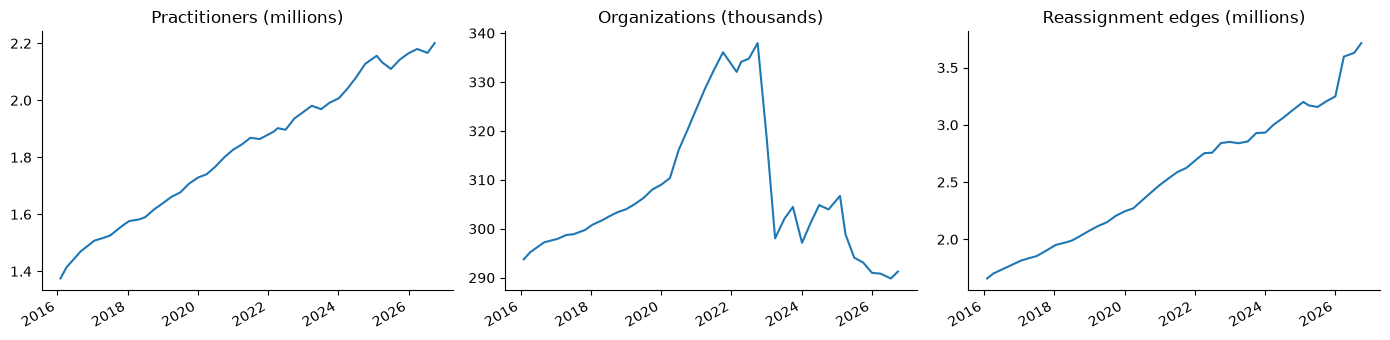

,n_practitioner,n_organization,n_hospital,n_reassignment,n_hospital_link,n_reassignment_rows,n_reassignment_dropped,n_hospital_enrollments
as_of_date,,,,,,,,
2016-02-01,1374813,293748,7168,1657888,8233,1723387,4099,9633
2019-04-01,1661343,305041,7106,2116414,8237,2200010,3898,9524
2022-04-12,1902265,334126,7288,2753109,8673,2885596,4259,10034
2022-12-30,1958170,319281,7274,2851231,8594,2993414,4192,9945
2023-03-31,1980794,298045,7256,2839606,8476,2986068,4215,9814
2026-01-02,2165294,290991,7023,3248781,8026,3469977,3611,9188
2026-04-01,2180085,290823,7022,3596693,8028,3857023,4156,9180
2026-09-29,2200672,291259,7031,3714552,7970,3996400,4041,9135


In [2]:
q = con.sql("SELECT * FROM quarters ORDER BY as_of_date").df().set_index("as_of_date")
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
(q[["n_practitioner"]] / 1e6).plot(ax=axes[0], legend=False, title="Practitioners (millions)")
(q[["n_organization"]] / 1e3).plot(ax=axes[1], legend=False, title="Organizations (thousands)")
(q[["n_reassignment"]] / 1e6).plot(ax=axes[2], legend=False, title="Reassignment edges (millions)")
for ax in axes: ax.set_xlabel("")
plt.tight_layout(); plt.show()
q.iloc[[0, 12, 24, 27, 28, 39, 40, -1], 1:]

Two breaks in these series come from the files, not from the market, and every measure below has to be read around them.

* **Late 2022 to early 2023: organizations fall by 40,000** (338,000 on 2022-09-30, 298,000 on 2023-03-31) while practitioners and edges keep growing. The organization enrollments that leave are mostly small ones; the share of physicians in one-physician organizations drops a point over the two quarters (section 3). It reads as a PECOS clean-up of inactive enrollments.
* **April 2026: 350,000 more edges in one quarter.** CMS began to publish the reassignments of physician assistants, who had almost none in the file before. The cell below shows it. Section 3 counts physicians only, so the measures below are not affected.

In [3]:
con.sql("""
WITH pa AS (
    SELECT q.as_of_date, p.pac_id
    FROM quarters q
    JOIN practitioner p ON p.effective_date <= q.as_of_date AND (p.end_date IS NULL OR p.end_date > q.as_of_date)
    WHERE list_contains(p.provider_type_codes, '14-97') AND q.as_of_date >= DATE '2025-07-01'),
edge AS (
    SELECT DISTINCT q.as_of_date, r.practitioner_pac_id
    FROM quarters q
    JOIN reassignment r ON r.effective_date <= q.as_of_date AND (r.end_date IS NULL OR r.end_date > q.as_of_date)
    WHERE q.as_of_date >= DATE '2025-07-01')
SELECT pa.as_of_date, count(*) AS physician_assistants_enrolled,
       count(edge.practitioner_pac_id) AS with_a_reassignment
FROM pa LEFT JOIN edge ON edge.as_of_date = pa.as_of_date AND edge.practitioner_pac_id = pa.pac_id
GROUP BY 1 ORDER BY 1
""").df()

,as_of_date,physician_assistants_enrolled,with_a_reassignment
0,2025-07-01,161822,650
1,2025-10-01,163912,1133
2,2026-01-02,167052,12333
3,2026-04-01,169512,167860
4,2026-07-17,171433,169633
5,2026-09-29,173356,171541


## 2. Linking organizations to hospitals

The POS file and the PPEF share no identifier. The PPEF practice-location file has only city, state and ZIP, and the release suppresses the NPPES "other identifier" slots where a hospital might have typed its CCN. So `graph-build` matches each hospital, critical access hospital or rural emergency hospital *enrollment* to an active POS hospital in the same state, through the NPPES practice address and phone of the enrollment's NPI: same phone and street number (rule 1), same street number within the ZIP (rule 2), or same phone (rule 3). An enrollment whose best rule ties between two CCNs is left unlinked, because ties are wrong a third to a half of the time.

CMS publishes the true link for recent months: the *Hospital Enrollments* file on data.cms.gov gives each hospital enrollment's CCN. `data/hospital_enrollments_2026-09-29.csv` is the file of the same date as the last PPEF quarter, cut to its identifiers. A third of its rows carry a CCN that is not a POS hospital: swing-bed, psychiatric-unit and rehabilitation-unit CCNs (`51Z312`, `44S058`) that share the hospital's address and enrollment, for which the file sometimes gives the parent CCN in `cah_or_hospital_ccn`. The check is therefore on the enrollments whose true CCN, or parent CCN, is a POS hospital.

In [4]:
con.execute("""
CREATE TABLE link_check AS
WITH pos AS (SELECT ccn FROM hospital WHERE end_date IS NULL),
truth AS (
    SELECT enrollment_id,
           CASE WHEN ccn IN (SELECT ccn FROM pos) THEN ccn
                WHEN cah_or_hospital_ccn IN (SELECT ccn FROM pos) THEN cah_or_hospital_ccn END AS true_ccn
    FROM read_csv('data/hospital_enrollments_2026-09-29.csv', all_varchar = true))
SELECT t.enrollment_id, t.true_ccn, l.ccn AS linked_ccn, l.match_rule
FROM truth t
LEFT JOIN hospital_link l ON l.enrollment_id = t.enrollment_id AND l.end_date IS NULL
WHERE t.true_ccn IS NOT NULL
""")
con.sql("""
SELECT coalesce(CAST(match_rule AS VARCHAR), 'not linked') AS match_rule, count(*) AS enrollments,
       count(*) FILTER (WHERE linked_ccn = true_ccn) AS correct,
       round(100 * count(*) FILTER (WHERE linked_ccn = true_ccn) / count(*), 1) AS precision_pct
FROM link_check GROUP BY ALL
UNION ALL
SELECT 'all', count(*), count(*) FILTER (WHERE linked_ccn = true_ccn),
       round(100 * count(*) FILTER (WHERE linked_ccn = true_ccn) / count(*), 1)
FROM link_check
ORDER BY 1
""").df()

,match_rule,enrollments,correct,precision_pct
0,1,3156,3155,100.0
1,2,1934,1916,99.1
2,3,173,168,97.1
3,all,5915,5239,88.6
4,not linked,652,0,0.0


Read `precision_pct` on the rule rows as precision and on the `all` row as recall: 89 percent of the linkable hospital enrollments get the right CCN, and a CCN the graph gives is right 97 to 100 percent of the time, depending on the rule. The check is for the last quarter only, the one with a true file; the rules are the same in every quarter, and the number of links tracks the number of hospital enrollments from 2016 on (`quarters.csv`: 8,233 of 9,633 in February 2016, 7,970 of 9,135 in September 2026).

Nothing below depends on the CCN link. It is in the graph so that hospitals' own attributes (beds, location, ownership type) can be attached to the organizations that bill for them: the step the literature calls rolling tax ids up to systems, which section 6 leaves for further work.

## 3. Group size: replicating Welch et al. (2013) and Muhlestein and Smith (2016)

Welch et al. defined a physician group as a Medicare tax id, sized it by the physicians billing under it, and put a physician who billed under several tax ids in the one with the most of their charges. They found the share of physicians in groups of more than 50 rising from 30.9 to 35.6 percent between 2009 and 2011. Muhlestein and Smith used Physician Compare's group ids, which are PECOS associate ids, the same ids this graph uses, and found the share in groups of 100 or more rising from 29.6 to 35.1 percent between June 2013 and December 2015, and the share in groups of nine or fewer falling from 40.1 to 35.3 percent.

The graph has their group id but not their claims, so it cannot pick a physician's main group. It shows two substitutes. **Fractional**: a physician with `k` reassignments counts `1/k` in each group, the convention when nothing ranks the groups. **Single group**: only the physicians who reassign to exactly one organization, for whom the choice does not arise (half of them). A physician is a practitioner whose NPPES primary taxonomy is an allopathic or osteopathic physician code (`20*`); group size is the number of such physicians reassigning to the organization that quarter.

In [5]:
con.execute("""
CREATE TABLE physician_q AS
SELECT q.as_of_date, p.pac_id, p.provider_type_codes, p.practice_zip5, p.practice_state
FROM quarters q
JOIN practitioner p ON p.effective_date <= q.as_of_date AND (p.end_date IS NULL OR p.end_date > q.as_of_date)
WHERE p.taxonomy_code LIKE '20%'
""")
con.execute("""
CREATE TABLE physician_edge AS
SELECT e.*, count(*) OVER (PARTITION BY e.as_of_date, e.practitioner_pac_id) AS k
FROM (SELECT q.as_of_date, r.practitioner_pac_id, r.organization_pac_id
      FROM quarters q
      JOIN reassignment r ON r.effective_date <= q.as_of_date AND (r.end_date IS NULL OR r.end_date > q.as_of_date)) e
SEMI JOIN physician_q p ON p.as_of_date = e.as_of_date AND p.pac_id = e.practitioner_pac_id
""")
con.execute("""
CREATE TABLE group_size AS
SELECT as_of_date, organization_pac_id, count(*) AS physicians FROM physician_edge GROUP BY ALL
""")
con.execute("""
CREATE TABLE size_shares AS
SELECT e.as_of_date, w.weighting,
       100 * sum(w.wt) FILTER (WHERE g.physicians <= 9) / sum(w.wt) AS "9 or fewer",
       100 * sum(w.wt) FILTER (WHERE g.physicians > 50) / sum(w.wt) AS "more than 50",
       100 * sum(w.wt) FILTER (WHERE g.physicians >= 100) / sum(w.wt) AS "100 or more",
       100 * sum(w.wt) FILTER (WHERE g.physicians >= 500) / sum(w.wt) AS "500 or more"
FROM physician_edge e
JOIN group_size g USING (as_of_date, organization_pac_id)
CROSS JOIN LATERAL (VALUES ('fractional', 1.0 / e.k), ('single group', CASE WHEN e.k = 1 THEN 1.0 ELSE 0.0 END)) w(weighting, wt)
GROUP BY ALL
""")
coverage = con.sql("""
SELECT p.as_of_date, count(*) AS physicians,
       count(*) FILTER (WHERE e.k IS NOT NULL) AS with_a_reassignment,
       count(*) FILTER (WHERE e.k = 1) AS with_one,
       avg(e.k) AS mean_reassignments
FROM physician_q p
LEFT JOIN (SELECT DISTINCT as_of_date, practitioner_pac_id, k FROM physician_edge) e
       ON e.as_of_date = p.as_of_date AND e.practitioner_pac_id = p.pac_id
GROUP BY 1 ORDER BY 1
""").df().set_index("as_of_date")
coverage.iloc[[0, 12, 24, 36, -1]].round(2)

,physicians,with_a_reassignment,with_one,mean_reassignments
as_of_date,,,,
2016-02-01,705387,638048,414377,1.62
2019-04-01,783455,707403,430444,1.78
2022-04-12,854975,781680,427223,2.01
2025-04-01,903114,825368,438817,2.09
2026-09-29,926673,854721,454639,2.13


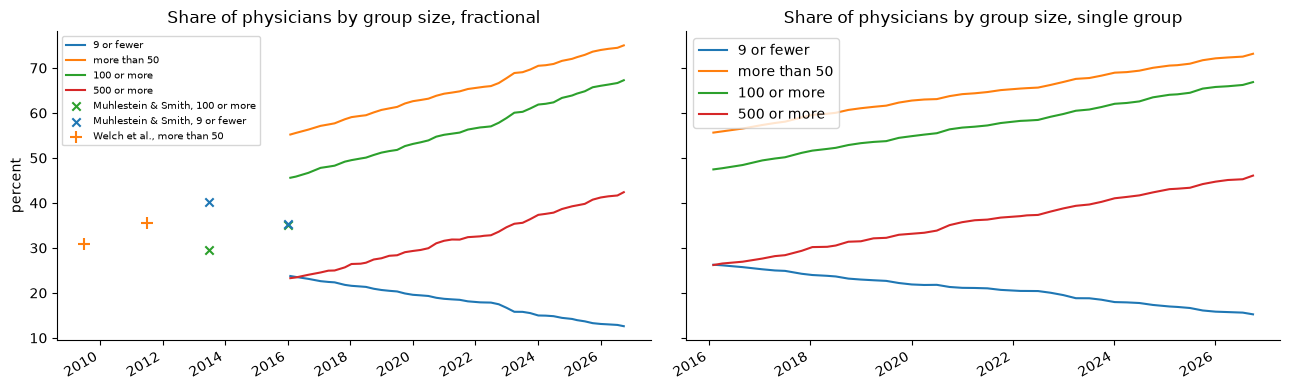

,as_of_date,weighting,9 or fewer,more than 50,100 or more,500 or more
0,2016-02-01,fractional,23.8,55.2,45.6,23.3
1,2016-02-01,single group,26.3,55.6,47.5,26.2
24,2019-04-01,fractional,20.5,61.0,51.5,28.3
25,2019-04-01,single group,22.8,61.4,53.6,32.1
48,2022-04-12,fractional,17.9,65.8,56.9,32.7
49,2022-04-12,single group,20.4,65.5,58.3,37.2
72,2025-04-01,fractional,13.9,72.4,64.3,39.5
73,2025-04-01,single group,16.9,70.6,64.1,43.2
84,2026-09-29,fractional,12.6,75.0,67.3,42.4
85,2026-09-29,single group,15.2,73.2,66.9,46.1


In [6]:
shares = con.sql("SELECT * FROM size_shares ORDER BY as_of_date, weighting").df()
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, (w, d) in zip(axes, shares.groupby("weighting")):
    d.set_index("as_of_date").drop(columns="weighting").plot(ax=ax, title=f"Share of physicians by group size, {w}")
    ax.set_xlabel(""); ax.set_ylabel("percent")
axes[0].scatter(pd.to_datetime(["2013-06-30", "2015-12-31"]), [29.6, 35.1], marker="x", color="C2", zorder=5,
                label="Muhlestein & Smith, 100 or more")
axes[0].scatter(pd.to_datetime(["2013-06-30", "2015-12-31"]), [40.1, 35.3], marker="x", color="C0", zorder=5,
                label="Muhlestein & Smith, 9 or fewer")
axes[0].scatter(pd.to_datetime(["2009-06-30", "2011-06-30"]), [30.9, 35.6], marker="+", s=80, color="C1", zorder=5,
                label="Welch et al., more than 50")
axes[0].legend(fontsize=7)
plt.tight_layout(); plt.show()
shares[shares.as_of_date.isin(shares.as_of_date.unique()[[0, 12, 24, 36, -1]])].round(1)

**The direction replicates and continues.** Under either weighting the share of physicians in groups of 100 or more rises by about 20 points over the decade (46 to 67 percent fractional, 48 to 67 percent single group) and the share in groups of nine or fewer falls by 40 to 50 percent. The trend is steady, with one extra step in the 2022-23 clean-up quarters, where small organizations left the file.

**The levels do not match the papers.** In February 2016, 46 percent of physicians are in groups of 100 or more by the fractional count and 48 percent among single-group physicians, against Muhlestein and Smith's 35 percent two months earlier. Both of our counts are higher, so the gap is not an artifact of how multi-group physicians are split. Three differences are known, and none can be removed with public data. Physician Compare showed a reassignment only if the pair had billed in the past 12 months, or the reassignment was less than six months old; the raw PPEF keeps every active reassignment. The papers' physicians are the ones with Medicare claims, while ours are everyone with a physician taxonomy and a reassignment. And Muhlestein and Smith's appendix, which defines their counting, was not available to us. The mean number of reassignments per physician with any rises by a third, from 1.6 to 2.1 (the table above), and the share with exactly one falls from 65 to 53 percent. That is consistent with stale reassignments piling up in a file that does not filter them, as well as with physicians really billing through more organizations (telehealth groups, hospitalist and locum companies). The graph alone cannot tell the two apart.

Muhlestein and Smith report the shift as larger for primary care physicians than for specialists. The same split, by Medicare specialty:

In [7]:
con.execute("""
CREATE TABLE physician_specialty AS
SELECT as_of_date, pac_id, practice_zip5, practice_state,
       CASE WHEN list_has_any(provider_type_codes, ['14-01', '14-08', '14-11', '14-37', '14-38']) THEN 'primary care'
            WHEN list_contains(provider_type_codes, '14-06') THEN 'cardiology'
            WHEN list_has_any(provider_type_codes, ['14-83', '14-90', '14-92']) THEN 'oncology'
            WHEN list_contains(provider_type_codes, '14-20') THEN 'orthopedic surgery'
            WHEN list_contains(provider_type_codes, '14-16') THEN 'obstetrics/gynecology'
            WHEN list_contains(provider_type_codes, '14-10') THEN 'gastroenterology'
            WHEN list_contains(provider_type_codes, '14-07') THEN 'dermatology'
       END AS specialty,
       list_has_any(provider_type_codes, ['14-01', '14-08', '14-11', '14-37', '14-38']) AS primary_care
FROM physician_q
""")
pc = con.sql("""
SELECT e.as_of_date, CASE WHEN s.primary_care THEN 'primary care' ELSE 'specialist' END AS physicians,
       100 * sum(1.0 / e.k) FILTER (WHERE g.physicians >= 100) / sum(1.0 / e.k) AS "100 or more",
       100 * sum(1.0 / e.k) FILTER (WHERE g.physicians <= 9) / sum(1.0 / e.k) AS "9 or fewer"
FROM physician_edge e
JOIN group_size g USING (as_of_date, organization_pac_id)
JOIN physician_specialty s ON s.as_of_date = e.as_of_date AND s.pac_id = e.practitioner_pac_id
GROUP BY ALL ORDER BY 1, 2
""").df()
pc.pivot(index="as_of_date", columns="physicians").iloc[[0, 12, 24, 36, -1]].round(1)

100 or more              9 or fewer           
physicians primary care specialist primary care specialist
as_of_date                                                
2016-02-01         50.3       43.0         22.5       24.5
2019-04-01         54.5       50.0         20.0       20.7
2022-04-12         59.3       55.6         17.8       17.9
2025-04-01         66.1       63.4         14.2       13.8
2026-09-29         68.4       66.7         13.1       12.3

Primary care physicians start in larger groups than specialists (50 against 43 percent in groups of 100 or more), but over the decade specialists gain more (24 points against 18) and leave small groups faster. Muhlestein and Smith's finding that the shift was larger in primary care held for 2013 to 2015; in this graph it does not hold for 2016 to 2026.

## 4. Market concentration: an HHI that public data cannot pin down

Capps, Dranove and Ody found 22 percent of physician markets highly concentrated in 2013 under the federal merger guidelines, and Fulton found primary care HHIs rising by about 29 percent between 2010 and 2016. Both papers used claims or vendor data to assign each physician to one firm and rolled practices up to the systems that own them; neither paper's market definition was available to us. The stated substitute: a market is a Dartmouth hospital referral region (by the physician's NPPES practice ZIP, `data/zip_hrr_2019.csv`) times a specialty group, a firm is an organization associate id, the share is the firm's share of the market's physicians, and a market is highly concentrated when its HHI exceeds 2,500 (the 2010 Horizontal Merger Guidelines; the 2023 guidelines lowered it to 1,800).

The same two weightings as in section 3:

In [8]:
con.execute("""
CREATE TABLE market_hhi AS
WITH m AS (
    SELECT e.as_of_date, w.weighting, h.hrr, s.specialty, e.organization_pac_id, sum(w.wt) AS physicians
    FROM physician_edge e
    JOIN physician_specialty s ON s.as_of_date = e.as_of_date AND s.pac_id = e.practitioner_pac_id
    JOIN hrr h ON h.zip5 = s.practice_zip5
    CROSS JOIN LATERAL (VALUES ('fractional', 1.0 / e.k), ('single group', CASE WHEN e.k = 1 THEN 1.0 END)) w(weighting, wt)
    WHERE s.specialty IS NOT NULL AND w.wt IS NOT NULL
    GROUP BY ALL)
SELECT as_of_date, weighting, hrr, specialty, sum(physicians) AS physicians,
       sum(power(100 * physicians, 2)) / power(sum(physicians), 2) AS hhi
FROM m GROUP BY ALL
""")
hhi = con.sql("""
SELECT year(as_of_date) AS year, weighting, specialty,
       100 * avg(CAST(hhi > 2500 AS INTEGER)) AS pct_highly_concentrated,
       median(hhi) AS median_hhi
FROM market_hhi
WHERE month(as_of_date) <= 2 AND year(as_of_date) IN (2016, 2018, 2020, 2022, 2024, 2026)
GROUP BY ALL ORDER BY specialty, weighting, year
""").df()
hhi.pivot(index=["specialty", "weighting"], columns="year", values="pct_highly_concentrated").round(1)

year                                2016  2018  2020  2022  2024  2026
specialty             weighting                                       
cardiology            fractional    21.6  18.6  17.0  15.0  14.7  15.7
                      single group  57.0  58.6  58.8  56.9  58.7  58.1
dermatology           fractional    31.7  29.7  28.4  24.2  25.2  26.5
                      single group  41.4  39.3  40.5  39.0  43.9  44.1
gastroenterology      fractional    40.8  38.2  35.0  32.7  30.4  30.4
                      single group  56.1  56.8  58.2  59.1  61.3  64.3
obstetrics/gynecology fractional    12.1   9.2   8.2   7.8   8.2   7.5
                      single group  23.5  25.8  26.1  28.1  30.1  34.4
oncology              fractional    34.4  33.7  31.4  26.5  25.5  25.8
                      single group  61.2  64.3  63.4  63.8  67.0  68.9
orthopedic surgery    fractional    22.9  20.3  19.6  17.3  16.3  18.3
                      single group  34.6  35.6  39.5  36.7  40.7  44.8
primary care          fractional     2.0   1.6   2.0   1.3   1.6   2.0
                      single group   8.5   8.8   8.5   7.8   8.2   9.8

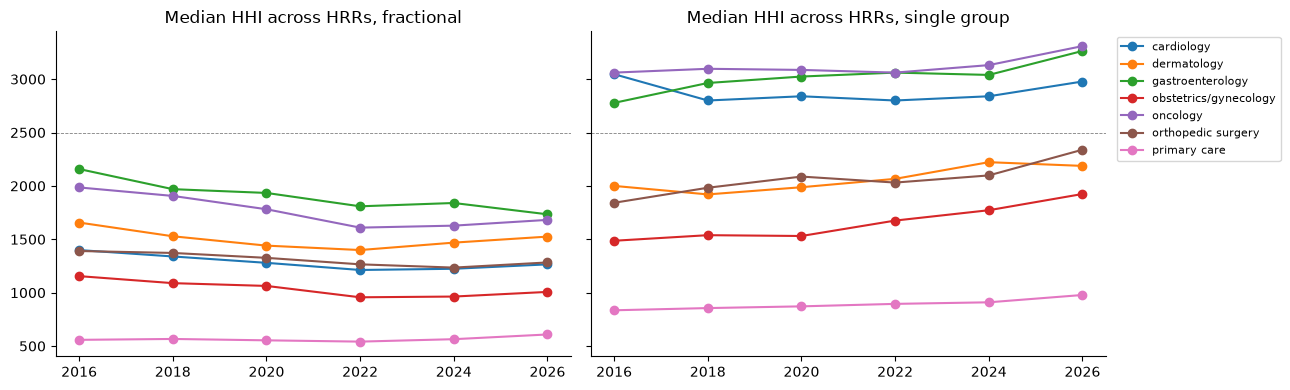

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, (w, d) in zip(axes, hhi.groupby("weighting")):
    d.pivot(index="year", columns="specialty", values="median_hhi").plot(ax=ax, marker="o", title=f"Median HHI across HRRs, {w}")
    ax.axhline(2500, color="grey", lw=0.6, ls="--"); ax.set_xlabel("")
axes[0].get_legend().remove()
axes[1].legend(bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)
plt.tight_layout(); plt.show()

**The two weightings disagree on the sign of the trend.** With fractional shares, the share of highly concentrated markets *falls* in every specialty but primary care, where it is flat. Among single-group physicians it is flat in primary care and cardiology and *rises* in the other five specialties, the direction of the literature. The cause is visible in section 3: as physicians add reassignments, fractional shares spread each of them over more firms, and the HHI falls mechanically, whether the extra reassignments are real or stale. The single-group sample has the opposite problem. It is half the physicians, and it is chosen by the very behavior (billing through one firm) that differs between small practices and large systems.

So the graph replicates the group-size trend but not an HHI trend. A defensible physician-market HHI needs what the papers had and the public files do not: a volume measure to choose each physician's main firm, and an ownership roll-up from tax ids to systems. The levels are not comparable to Capps, Dranove and Ody either way, because their firms are systems and ours are tax ids, which understates concentration wherever a system bills through several tax ids.

Section 4b supplies the first of the two from a second public source.

## 4b. Choosing the main group with Medicaid volume

The rule both papers use needs each physician's billing by firm. The public Medicare files do not have it, but HHS's public extract of Medicaid claims (T-MSIS, on [opendata.hhs.gov](https://opendata.hhs.gov/)) does for Medicaid: paid amounts by billing NPI, servicing NPI, HCPCS code and month, 2018 to 2024. A billing NPI belongs to an organization associate id in the graph, and a servicing NPI to a practitioner, so each reassignment edge can be given the Medicaid dollars it carried.

The rule, in the papers' terms:

* **Window.** Medicaid paid in calendar year `Y` ranks the reassignments in force on the first graph quarter on or after 31 December `Y`, a 12-month look-back like Physician Compare's billing filter.
* **Plurality.** A physician with one reassignment keeps it. A physician with several is assigned to the one with the most Medicaid paid, as Welch et al. and Capps, Dranove and Ody assign by plurality of charges. A physician with several and no Medicaid paid on any is left out.
* **Majority.** A stricter variant keeps only assignments where the main group carries at least half of the physician's Medicaid paid across their reassignments, in the spirit of Luo et al.'s "primarily".
* **States.** Medicaid billing reaches the graph unevenly by state (the cell below). States where fewer than a quarter of multi-group physicians can be assigned, pooled over the seven quarters and counting states with at least 1,000 such physician-quarters, are left out of every weighting in this section, as Zhu et al. dropped state-years with unusable T-MSIS data. The 25 percent line is ours; the paper's exclusions are in its appendix, which was not available to us.

Medicaid volume is not Medicare volume. A physician's main Medicaid group can differ from their main Medicare group, specialties that see few Medicaid patients are thin, and the extract drops every billing NPI, servicing NPI, code and month with fewer than 12 patients or claim lines. Suppression matters here only when all of a physician's Medicaid billing is in small cells (then they are left out) or when it spreads a group's volume over many small cells (then a smaller group can win).

In [10]:
con.execute("""
CREATE TABLE medicaid_volume AS
WITH y AS (SELECT DISTINCT year(month) AS y FROM medicaid_spending),
q AS (SELECT y.y, min(q.as_of_date) AS as_of_date FROM y JOIN quarters q ON q.as_of_date >= make_date(y.y, 12, 31) GROUP BY 1),
pr AS (SELECT q.y, q.as_of_date, p.pac_id, p.npi FROM q
       JOIN practitioner p ON p.effective_date <= q.as_of_date AND (p.end_date IS NULL OR p.end_date > q.as_of_date)),
og AS (SELECT q.as_of_date, o.pac_id, unnest(o.npis) AS npi FROM q
       JOIN organization o ON o.effective_date <= q.as_of_date AND (o.end_date IS NULL OR o.end_date > q.as_of_date)),
s AS (SELECT year(month) AS y, billing_npi, servicing_npi, sum(paid) AS paid
      FROM medicaid_spending WHERE billing_npi <> servicing_npi GROUP BY ALL)
SELECT pr.as_of_date, pr.pac_id AS practitioner_pac_id, og.pac_id AS organization_pac_id, sum(s.paid) AS medicaid_paid
FROM s
JOIN pr ON pr.y = s.y AND pr.npi = s.servicing_npi
JOIN og ON og.as_of_date = pr.as_of_date AND og.npi = s.billing_npi
GROUP BY ALL
""")
con.execute("""
CREATE TABLE main_group AS
WITH e AS (
    SELECT e.as_of_date, e.practitioner_pac_id, e.organization_pac_id, e.k, coalesce(v.medicaid_paid, 0) AS paid,
           sum(coalesce(v.medicaid_paid, 0)) OVER (PARTITION BY e.as_of_date, e.practitioner_pac_id) AS physician_paid
    FROM physician_edge e
    LEFT JOIN medicaid_volume v USING (as_of_date, practitioner_pac_id, organization_pac_id)
    WHERE e.as_of_date IN (SELECT DISTINCT as_of_date FROM medicaid_volume))
SELECT as_of_date, practitioner_pac_id, organization_pac_id, k,
       CASE WHEN k = 1 THEN 1.0 ELSE paid / physician_paid END AS share
FROM e
WHERE k = 1 OR paid > 0
QUALIFY row_number() OVER (PARTITION BY as_of_date, practitioner_pac_id ORDER BY paid DESC, organization_pac_id) = 1
""")
con.execute("""
CREATE TABLE state_coverage AS
SELECT s.practice_state,
       count(DISTINCT (e.as_of_date, e.practitioner_pac_id)) AS multi_group_physicians,
       100 * count(DISTINCT (m.as_of_date, m.practitioner_pac_id)) / count(DISTINCT (e.as_of_date, e.practitioner_pac_id)) AS pct_assigned,
       pct_assigned < 25 AND multi_group_physicians >= 1000 AS screened_out
FROM physician_edge e
JOIN physician_specialty s ON s.as_of_date = e.as_of_date AND s.pac_id = e.practitioner_pac_id
LEFT JOIN main_group m ON m.as_of_date = e.as_of_date AND m.practitioner_pac_id = e.practitioner_pac_id
WHERE e.k > 1 AND e.as_of_date IN (SELECT DISTINCT as_of_date FROM main_group)
GROUP BY 1
""")
cov = con.sql("""
WITH two AS (
    SELECT v.as_of_date, v.practitioner_pac_id
    FROM medicaid_volume v
    SEMI JOIN physician_edge e USING (as_of_date, practitioner_pac_id, organization_pac_id)
    GROUP BY ALL HAVING count(*) >= 2)
SELECT e.as_of_date, count(DISTINCT e.practitioner_pac_id) FILTER (WHERE e.k > 1) AS multi_group_physicians,
       count(DISTINCT m.practitioner_pac_id) FILTER (WHERE m.k > 1) AS assigned_plurality,
       count(DISTINCT m.practitioner_pac_id) FILTER (WHERE m.k > 1 AND m.share >= 0.5) AS assigned_majority,
       count(DISTINCT t.practitioner_pac_id) AS paid_by_two_or_more
FROM physician_edge e
LEFT JOIN main_group m USING (as_of_date, practitioner_pac_id)
LEFT JOIN two t USING (as_of_date, practitioner_pac_id)
WHERE e.as_of_date IN (SELECT DISTINCT as_of_date FROM main_group)
GROUP BY 1 ORDER BY 1
""").df().set_index("as_of_date")
cov["pct_plurality"] = 100 * cov.assigned_plurality / cov.multi_group_physicians
print("states screened out:", con.sql("SELECT string_agg(practice_state || ' ' || round(pct_assigned)::INT || '%', ', ' ORDER BY pct_assigned) FROM state_coverage WHERE screened_out").fetchone()[0])
cov.round(1)

states screened out: MI 9%, IL 10%, SD 18%, UT 21%, GA 23%, DE 24%


,multi_group_physicians,assigned_plurality,assigned_majority,paid_by_two_or_more,pct_plurality
as_of_date,,,,,
2018-12-31,272535,109368,108941,21363,40.1
2020-01-02,290546,119528,119005,23168,41.1
2020-12-31,318468,136786,136278,24225,43.0
2022-02-24,351822,157268,156675,27522,44.7
2023-03-31,362749,162571,161858,29698,44.8
2024-01-05,373849,168294,167382,32019,45.0
2025-02-03,390897,160667,159957,26511,41.1


Group size under the main-group rule, next to the two weightings of section 3 on the same quarters and states:

In [11]:
con.execute("""
CREATE TABLE weighted_edge AS
WITH e AS (
    SELECT e.as_of_date, e.practitioner_pac_id, e.organization_pac_id, e.k, m.share
    FROM physician_edge e
    JOIN physician_specialty s ON s.as_of_date = e.as_of_date AND s.pac_id = e.practitioner_pac_id
    LEFT JOIN main_group m ON m.as_of_date = e.as_of_date AND m.practitioner_pac_id = e.practitioner_pac_id
                          AND m.organization_pac_id = e.organization_pac_id
    WHERE e.as_of_date IN (SELECT DISTINCT as_of_date FROM main_group)
      AND s.practice_state NOT IN (SELECT practice_state FROM state_coverage WHERE screened_out))
SELECT e.as_of_date, e.practitioner_pac_id, e.organization_pac_id, w.weighting, w.wt
FROM e
CROSS JOIN LATERAL (VALUES ('fractional', 1.0 / e.k),
                           ('single group', CASE WHEN e.k = 1 THEN 1.0 END),
                           ('Medicaid plurality', CASE WHEN e.share IS NOT NULL THEN 1.0 END),
                           ('Medicaid majority', CASE WHEN e.share >= 0.5 THEN 1.0 END)) w(weighting, wt)
WHERE w.wt IS NOT NULL
""")
weighted_sizes = con.sql("""
SELECT e.as_of_date, e.weighting,
       100 * sum(e.wt) FILTER (WHERE g.physicians <= 9) / sum(e.wt) AS "9 or fewer",
       100 * sum(e.wt) FILTER (WHERE g.physicians >= 100) / sum(e.wt) AS "100 or more"
FROM weighted_edge e
JOIN group_size g USING (as_of_date, organization_pac_id)
GROUP BY ALL ORDER BY 1, 2
""").df()
weighted_sizes.pivot(index="as_of_date", columns="weighting").round(1)

9 or fewer                                                  100 or more                                           
weighting  Medicaid majority Medicaid plurality fractional single group Medicaid majority Medicaid plurality fractional single group
as_of_date                                                                                                                          
2018-12-31              21.5               21.5       20.5         22.8              51.6               51.6       51.4         53.4
2020-01-02              20.4               20.4       19.4         21.7              53.1               53.1       53.3         54.9
2020-12-31              19.5               19.5       18.5         20.9              55.2               55.1       55.4         56.9
2022-02-24              18.5               18.5       17.7         20.2              56.9               56.9       57.1         58.4
2023-03-31              17.1               17.1       15.7         18.6              59.2               59.2       60.2         60.6
2024-01-05              16.3               16.3       14.9         17.8              61.0               61.0       62.1         62.2
2025-02-03              15.5               15.5       14.1         16.8              63.0               63.0       64.1         64.2

And the HHI of section 4 under all four weightings:

In [12]:
con.execute("""
CREATE TABLE weighted_hhi AS
WITH m AS (
    SELECT e.as_of_date, e.weighting, h.hrr, s.specialty, e.organization_pac_id, sum(e.wt) AS physicians
    FROM weighted_edge e
    JOIN physician_specialty s ON s.as_of_date = e.as_of_date AND s.pac_id = e.practitioner_pac_id
    JOIN hrr h ON h.zip5 = s.practice_zip5
    WHERE s.specialty IS NOT NULL
    GROUP BY ALL)
SELECT as_of_date, weighting, hrr, specialty, sum(physicians) AS physicians,
       sum(power(100 * physicians, 2)) / power(sum(physicians), 2) AS hhi
FROM m GROUP BY ALL
""")
whhi = con.sql("""
SELECT as_of_date, weighting, specialty, 100 * avg(CAST(hhi > 2500 AS INTEGER)) AS pct_highly_concentrated, median(hhi) AS median_hhi
FROM weighted_hhi GROUP BY ALL ORDER BY ALL
""").df()
first, last = whhi.as_of_date.min(), whhi.as_of_date.max()
change = whhi[whhi.as_of_date.isin([first, last])].pivot(index=["specialty", "weighting"], columns="as_of_date", values="pct_highly_concentrated")
change.columns = [str(c.date()) for c in change.columns]
change["change"] = change.iloc[:, 1] - change.iloc[:, 0]
change.round(1)

2018-12-31  2025-02-03  change
specialty             weighting                                         
cardiology            Medicaid majority         47.2        46.7    -0.5
                      Medicaid plurality        47.2        46.7    -0.5
                      fractional                17.8        13.7    -4.1
                      single group              58.9        60.5     1.5
dermatology           Medicaid majority         38.1        39.3     1.1
                      Medicaid plurality        38.1        39.3     1.1
                      fractional                32.5        24.0    -8.5
                      single group              40.9        45.5     4.6
gastroenterology      Medicaid majority         51.9        52.2     0.4
                      Medicaid plurality        51.9        52.2     0.4
                      fractional                37.9        31.2    -6.7
                      single group              57.4        63.6     6.2
obstetrics/gynecology Medicaid majority         22.4        24.3     1.8
                      Medicaid plurality        22.4        24.3     1.8
                      fractional                 9.9         9.2    -0.7
                      single group              30.9        33.0     2.1
oncology              Medicaid majority         57.6        58.7     1.1
                      Medicaid plurality        57.6        58.7     1.1
                      fractional                34.4        29.3    -5.2
                      single group              63.3        70.2     6.9
orthopedic surgery    Medicaid majority         34.2        33.8    -0.4
                      Medicaid plurality        34.2        33.8    -0.4
                      fractional                21.0        16.5    -4.4
                      single group              39.0        43.9     4.9
primary care          Medicaid majority          7.6         6.9    -0.7
                      Medicaid plurality         7.6         6.9    -0.7
                      fractional                 3.6         3.6     0.0
                      single group               9.7        11.2     1.5

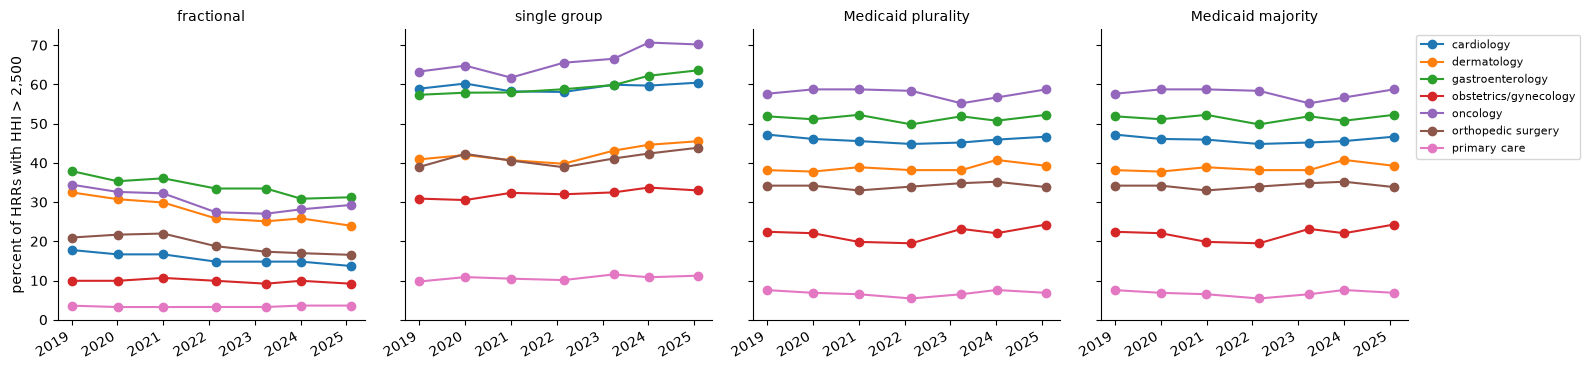

In [13]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8), sharey=True)
for ax, w in zip(axes, ["fractional", "single group", "Medicaid plurality", "Medicaid majority"]):
    d = whhi[whhi.weighting == w]
    if len(d):
        d.pivot(index="as_of_date", columns="specialty", values="pct_highly_concentrated").plot(ax=ax, marker="o", legend=False)
    ax.set_title(w, fontsize=10); ax.set_xlabel("")
axes[0].set_ylabel("percent of HRRs with HHI > 2,500")
if axes[-1].lines:
    axes[-1].legend(bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)
plt.tight_layout(); plt.show()

**Medicaid volume can rank the groups of four in ten multi-group physicians**: 40 to 45 percent each quarter, out of 270,000 to 390,000. The rest bill Medicaid only under their own NPI, in suppressed cells, in states the extract misses, or not at all. Majority and plurality give nearly the same answer, because only 21,000 to 32,000 physicians a quarter have Medicaid volume on two or more of their groups. For most multi-group physicians the Medicaid dollars land on exactly one of their Medicare reassignments, and the others carry none. That fits the stale-reassignment reading of section 3, but Medicaid billing alone cannot prove it: a reassignment can carry Medicare claims and no Medicaid claims.

**Group size does not depend on the weighting.** Between the end of 2018 and February 2025 the share of physicians in groups of 100 or more rises from 52 to 63 percent under the Medicaid rule, against 51 to 64 fractional and 53 to 64 single group. The section 3 result holds, and the levels stay about 10 points above Muhlestein and Smith's whichever way multi-group physicians are counted. The level gap is not a weighting artifact.

**The HHI trend is flat under the papers' rule.** With each physician in their Medicaid main group, the share of highly concentrated markets moves by less than two points in every specialty between 2018 and 2025: down 0.7 in primary care and 0.5 in cardiology, up 1.8 in obstetrics and gynecology and 1.1 in dermatology and oncology. The two substitutes of section 4 bracket it: fractional falls in six of seven specialties (by up to 8.5 points), single group rises in all seven (by up to 6.9). The bracketing is what section 4's explanation predicts. Fractional shares fall mechanically as physicians add reassignments. The single-group sample loses exactly the physicians who add groups. The Medicaid rule keeps those physicians and puts each in one firm, and its trend lies between the two substitutes, near zero.

So at the tax-id level, on the papers' assignment rule, physician markets by HRR and specialty were about as concentrated in early 2025 as at the end of 2018. Physicians moved into large groups over the same years without raising market HHIs; the graph does not say which markets absorbed the growth, and that is the next question to ask of it. This is not a test of Fulton's or Capps, Dranove and Ody's findings. Their windows end in 2016 and 2013, their firms are systems, and the Medicaid rule covers only the multi-group physicians who bill Medicaid through a group, outside the six screened states. A system-level HHI still needs the ownership roll-up of section 6.

## 5. Physicians billing through hospital entities: a lower bound on vertical integration

Luo et al. (2024) call a physician vertically integrated when they bill primarily through a hospital-related tax id. They find the share rising from 19 percent in 1999 to 43 percent in 2019, and they show that the simplest version, counting only tax ids that themselves bill as a hospital, finds about 30 percent of the hospital-related tax ids their full method finds. That simple version is the one the graph supports: an organization is a hospital entity when its associate id holds a hospital, critical access hospital or rural emergency hospital enrollment, or a Part B hospital department enrollment. Shown with both weightings, plus "any": a physician with at least one reassignment to a hospital entity.

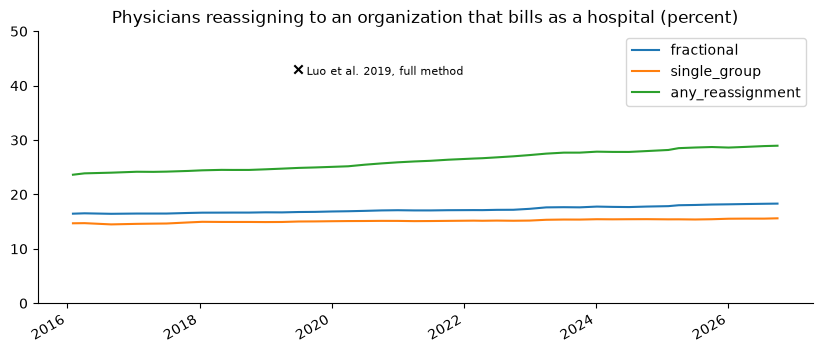

,fractional,single_group,any_reassignment
as_of_date,,,
2016-02-01,16.5,14.7,23.6
2019-04-01,16.7,14.9,24.7
2022-04-12,17.1,15.2,26.7
2025-04-01,18.0,15.4,28.5
2026-09-29,18.3,15.6,29.0


In [14]:
vi = con.sql("""
WITH oq AS (
    SELECT q.as_of_date, o.pac_id, o.hospital
    FROM quarters q
    JOIN organization o ON o.effective_date <= q.as_of_date AND (o.end_date IS NULL OR o.end_date > q.as_of_date))
SELECT e.as_of_date,
       100 * sum(1.0 / e.k) FILTER (WHERE oq.hospital) / sum(1.0 / e.k) AS fractional,
       100 * count(*) FILTER (WHERE oq.hospital AND e.k = 1) / count(*) FILTER (WHERE e.k = 1) AS single_group,
       100 * count(DISTINCT e.practitioner_pac_id) FILTER (WHERE oq.hospital) / count(DISTINCT e.practitioner_pac_id) AS any_reassignment
FROM physician_edge e
JOIN oq ON oq.as_of_date = e.as_of_date AND oq.pac_id = e.organization_pac_id
GROUP BY 1 ORDER BY 1
""").df().set_index("as_of_date")
ax = vi.plot(title="Physicians reassigning to an organization that bills as a hospital (percent)")
ax.scatter(pd.to_datetime(["2019-06-30"]), [43], marker="x", color="k", zorder=5)
ax.annotate("Luo et al. 2019, full method", (pd.Timestamp("2019-06-30"), 43), textcoords="offset points", xytext=(6, -4), fontsize=8)
ax.set_xlabel(""); ax.set_ylim(0, 50); plt.show()
vi.iloc[[0, 12, 24, 36, -1]].round(1)

In [15]:
con.sql("""
WITH oq AS (
    SELECT q.as_of_date, o.pac_id, o.hospital
    FROM quarters q
    JOIN organization o ON o.effective_date <= q.as_of_date AND (o.end_date IS NULL OR o.end_date > q.as_of_date))
SELECT s.specialty,
       100 * sum(1.0 / e.k) FILTER (WHERE oq.hospital AND year(e.as_of_date) = 2016) / sum(1.0 / e.k) FILTER (WHERE year(e.as_of_date) = 2016) AS pct_2016,
       100 * sum(1.0 / e.k) FILTER (WHERE oq.hospital AND year(e.as_of_date) = 2026) / sum(1.0 / e.k) FILTER (WHERE year(e.as_of_date) = 2026) AS pct_2026
FROM physician_edge e
JOIN oq ON oq.as_of_date = e.as_of_date AND oq.pac_id = e.organization_pac_id
JOIN physician_specialty s ON s.as_of_date = e.as_of_date AND s.pac_id = e.practitioner_pac_id
WHERE month(e.as_of_date) <= 2 AND year(e.as_of_date) IN (2016, 2026) AND s.specialty IS NOT NULL
GROUP BY 1 ORDER BY pct_2026 DESC
""").df().round(1)

,specialty,pct_2016,pct_2026
0,cardiology,22.5,23.7
1,oncology,18.9,22.7
2,primary care,18.1,19.0
3,orthopedic surgery,12.8,17.4
4,obstetrics/gynecology,14.9,16.7
5,gastroenterology,12.0,15.4
6,dermatology,7.2,7.3


The share rises slowly and steadily under every weighting (16.5 to 18.3 percent fractional, 23.6 to 29.0 percent with any hospital reassignment), and its level, a quarter of physicians with any hospital reassignment in 2019, sits below Luo et al.'s 43 percent, as a basic-tax-id measure must. By specialty it is highest in cardiology and oncology, as Nikpay, Richards and Penson (*Health Affairs* 2018) found with vendor data, but it moves by one to four points over the decade, far less than the 34 points they report for 2007 to 2017; most of the integration they measured does not run through a hospital's own tax id. The literature's warnings apply in full. Hospitals buy practices and keep billing through the practice's own tax id, or through a system's physician-group entity that has no hospital enrollment, and the graph cannot see either. Treat this series as a floor whose movement, not level, carries information.

## 6. What the graph cannot say, and next steps

* **A reassignment is a billing permission, not employment or ownership.** The AHRQ Compendium of U.S. Health Systems declined to use PECOS for that reason, and because one system can spread its physicians over many tax ids.
* **The PPEF has no volume.** Every rule the papers use to choose a physician's main firm (plurality of charges, 50 percent of allowed amounts) needs claims, and section 4 shows the choice changes the answer. Section 4b borrows Medicaid volume, which covers four in ten multi-group physicians, from 2018 to 2024.
* **An associate id is a tax id, not a system.** System membership needs an ownership layer.

Next steps, each a published measure the graph is now ready for, not done here:

1. **Ownership edges.** CMS publishes monthly *All Owners* files for hospitals, nursing homes, home health agencies and hospices since late 2022: each facility enrollment's direct and indirect owners, by associate id, with percentages, association dates and flags for private equity, REIT and holding-company owners. ASPE (Welch, Xu, De Lew and Sommers, 2023) inferred ultimate owners and chain sizes from the hospital file. Loading them adds owner -> organization edges keyed by the same associate ids as this graph.
2. **Systems.** Luo et al. put tax ids under common control into one component with a network of IRS Form 990 Schedule R filings. The graph supports the same component step on ownership edges, validated against the AHRQ Compendium's hospital linkage file, which lists each system's CCNs.
3. **Other facility types.** The hospital link extends to nursing homes, home health agencies, hospices and dialysis facilities through the same address rules and the iQIES POS file.
4. **A claims-based main group.** The public *Doctors and Clinicians* file (formerly Physician Compare) lists each clinician's group associate ids after CMS's 12-month billing filter, and hospital affiliations by CCN. Its archived editions (quarterly from 2014, captured by the Internet Archive through 2022) would show how much of section 3's level gap is stale reassignments, and give a second, Medicare-side main-group rule to set beside section 4b's.